In [17]:
import numpy as np
import matplotlib.pyplot as plt
import copy, math

In [3]:
def load_house_data():
    data = np.loadtxt("./houses.txt", delimiter=',', skiprows=1)
    X = data[:,:4]
    y = data[:,4]
    return X, y

In [6]:
X_train, y_train = load_house_data()
X_features = ['size(sqft)','bedrooms','floors','age']

In [8]:
print(X_features)

['size(sqft)', 'bedrooms', 'floors', 'age']


Gradient descent for multiple variables:

$$\begin{align*} \text{repeat}&\text{ until convergence:} \; \lbrace \newline\;
& w_j = w_j -  \alpha \frac{\partial J(\mathbf{w},b)}{\partial w_j} \tag{5}  \; & \text{for j = 0..n-1}\newline
&b\ \ = b -  \alpha \frac{\partial J(\mathbf{w},b)}{\partial b}  \newline \rbrace
\end{align*}$$

where, n is the number of features, parameters $w_j$,  $b$, are updated simultaneously and where  

$$
\begin{align}
\frac{\partial J(\mathbf{w},b)}{\partial w_j}  &= \frac{1}{m} \sum\limits_{i = 0}^{m-1} (f_{\mathbf{w},b}(\mathbf{x}^{(i)}) - y^{(i)})x_{j}^{(i)} \tag{6}  \\
\frac{\partial J(\mathbf{w},b)}{\partial b}  &= \frac{1}{m} \sum\limits_{i = 0}^{m-1} (f_{\mathbf{w},b}(\mathbf{x}^{(i)}) - y^{(i)}) \tag{7}
\end{align}
$$
* m is the number of training examples in the data set

    
*  $f_{\mathbf{w},b}(\mathbf{x}^{(i)})$ is the model's prediction, while $y^{(i)}$ is the target value

In [18]:
# add history, append each iteration's cost
def gradient_descent(X, y, w_in, b_in, cost_function, gradient_function, alpha, num_iters):
    w = copy.deepcopy(w_in)  #avoid modifying global w within function
    b = b_in
    hist = []                                  # <-- new
    for i in range(num_iters):
        dj_db, dj_dw = gradient_function(X, y, w, b)
        w = w - alpha * dj_dw
        b = b - alpha * dj_db
        hist.append(cost_function(X, y, w, b)) # <-- new
    return w, b, hist                          # <-- new

In [19]:
def compute_gradient(X, y, w, b):
    m, n = X.shape
    dj_dw = np.zeros((n,))
    dj_db = 0.
    for i in range(m):
        err = (np.dot(X[i], w) + b) - y[i]
        for j in range(n):
            dj_dw[j] += err * X[i][j]
        dj_db = dj_db + err
    dj_dw = dj_dw / m
    dj_db = dj_db / m
    return dj_db, dj_dw

In [10]:
def compute_cost(X, y, w, b):
    m = X.shape[0]
    cost = 0.0
    for i in range(m):
        f_wb_i = np.dot(X[i], w) + b
        cost += (f_wb_i - y[i]) ** 2
    cost = cost / (2 * m)
    return cost

In [11]:
def plot_cost(hist):
    plt.plot(hist)
    plt.xlabel("iteration")
    plt.ylabel("cost J")
    plt.title("Cost vs iteration")
    plt.grid(True)
    plt.show()

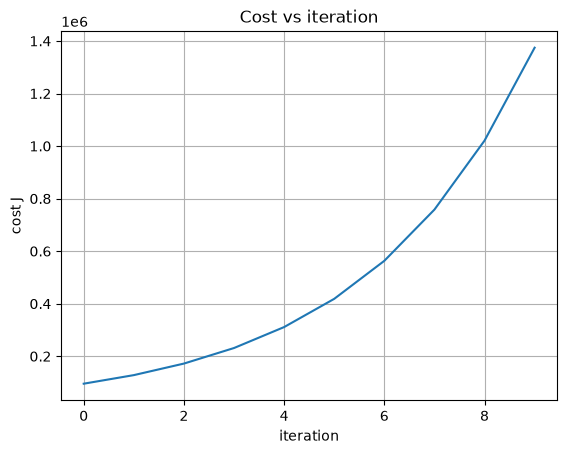

In [20]:
w, b, hist = gradient_descent(
    X_train, y_train,
    np.zeros(X_train.shape[1]), 0.,   # initial_w, initial_b
    compute_cost, compute_gradient,
    alpha=9.9e-7, num_iters=10
)
plot_cost(hist)

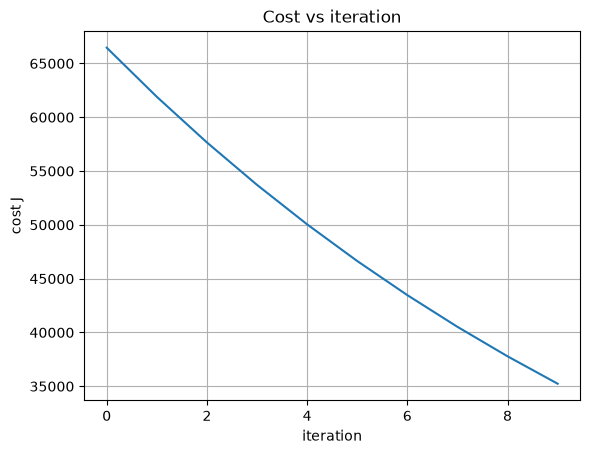

In [21]:
w, b, hist = gradient_descent(
    X_train, y_train,
    np.zeros(X_train.shape[1]), 0.,   # initial_w, initial_b
    compute_cost, compute_gradient,
    alpha=9e-7, num_iters=10
)
plot_cost(hist)

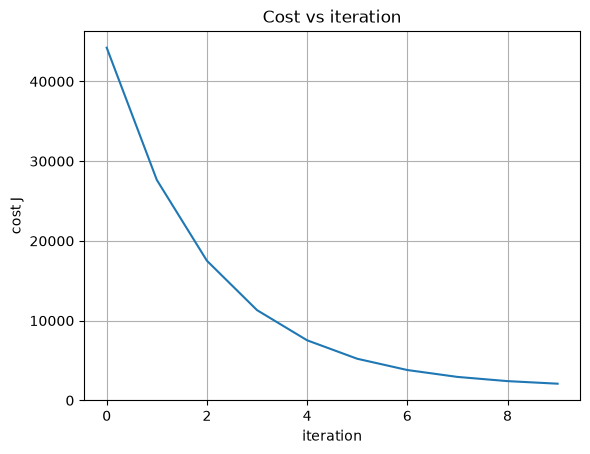

In [22]:
w, b, hist = gradient_descent(
    X_train, y_train,
    np.zeros(X_train.shape[1]), 0.,   # initial_w, initial_b
    compute_cost, compute_gradient,
    alpha=1e-7, num_iters=10
)
plot_cost(hist)

In [23]:
def zscore_normalize_features(X):
    mu     = np.mean(X, axis=0) 
    sigma  = np.std(X, axis=0)
    X_norm = (X - mu) / sigma      
    return (X_norm, mu, sigma)

In [24]:
X_norm, X_mu, X_sigma = zscore_normalize_features(X_train)

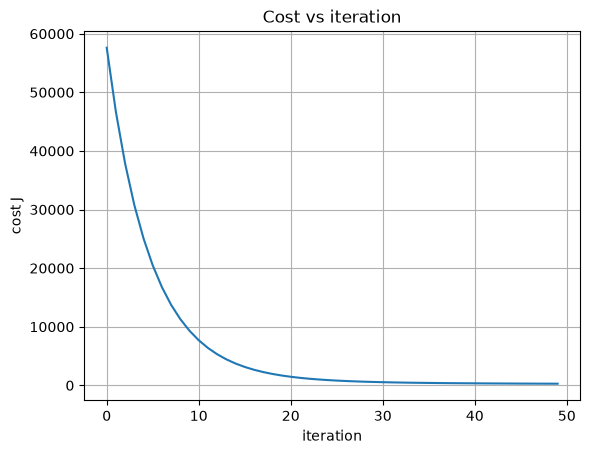

In [31]:
w_norm, b_norm, hist = gradient_descent(
    X_norm, y_train,
    np.zeros(X_norm.shape[1]), 0.,
    compute_cost, compute_gradient,
    alpha=1.0e-1, num_iters=50
)
plot_cost(hist)